In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('../report', exist_ok=True)

# 1. Đọc dữ liệu dataset.csv và chuẩn hóa tên cột
df = pd.read_csv('../data/raw/dataset.csv', encoding='ISO-8859-1')
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

print(f"Kích thước dữ liệu gốc: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print("Danh sách các cột:", list(df.columns))
print("\n=== KIỂU DỮ LIỆU & DỮ LIỆU THIẾU ===")
print(pd.DataFrame({
    'kieu_du_lieu': df.dtypes,
    'so_luong_thieu': df.isnull().sum(),
    'ty_le_thieu (%)': (df.isnull().mean() * 100).round(2)
}))
print(f"\nSố dòng trùng lặp: {df.duplicated().sum():,}")
df.head()

Kích thước dữ liệu gốc: 541,910 dòng x 8 cột
Danh sách các cột: ['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country']

=== KIỂU DỮ LIỆU & DỮ LIỆU THIẾU ===
            kieu_du_lieu  so_luong_thieu  ty_le_thieu (%)
invoice              str               0             0.00
stockcode            str               0             0.00
description          str            1454             0.27
quantity           int64               0             0.00
invoicedate          str               0             0.00
price            float64               0             0.00
customer_id      float64          135080            24.93
country              str               0             0.00

Số dòng trùng lặp: 5,268


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


Số dòng quantity <= 0 (đơn hủy/trả hàng): 10,624
Số dòng price <= 0 (giá bằng 0 hoặc âm): 2,517
Số hóa đơn bắt đầu bằng 'C' (Cancelled): 9,288

Số dòng hợp lệ (quantity > 0 & price > 0): 530,105
Khoảng thời gian dữ liệu: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Số mã sản phẩm (stockcode) duy nhất: 3,922
Số hóa đơn (invoice) hợp lệ duy nhất: 19,960
Số quốc gia (country) duy nhất: 38

Số dòng sau tổng hợp (Sản phẩm x Tuần): 101,579
Số tuần quan sát duy nhất: 53

=== THỐNG KÊ MÔ TẢ BIẾN MỤC TIÊU SALES (DOANH THU/TUẦN) ===
count    101579.00
mean        105.01
std         665.92
min           0.00
25%          10.08
50%          29.70
75%          88.44
max      168469.60
Name: sales, dtype: float64
Độ lệch (Skewness) của sales: 177.94


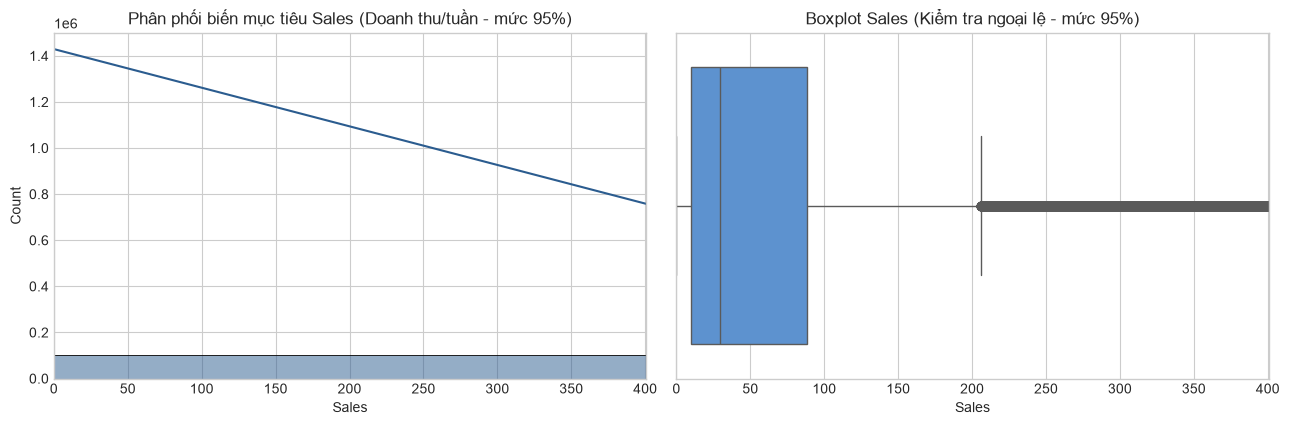

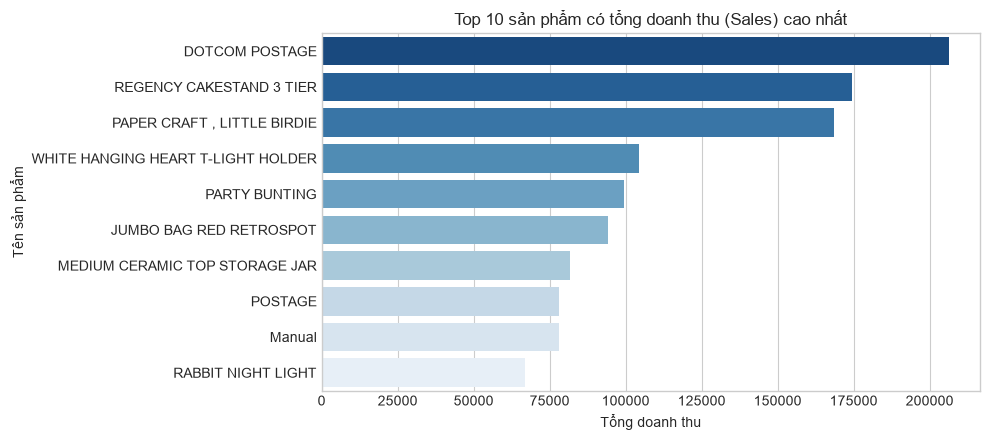

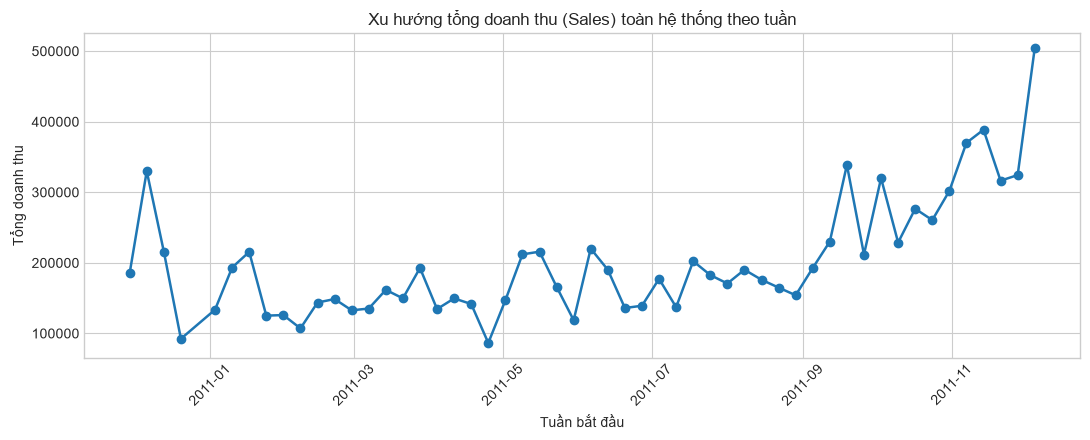

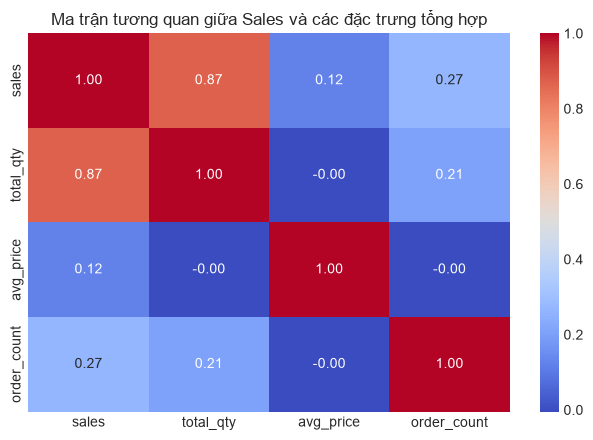

In [3]:
# 2. Kiểm tra bất thường, thời gian & tổng hợp biến mục tiêu sales theo (stockcode, week_start)
print(f"Số dòng quantity <= 0 (đơn hủy/trả hàng): {(df['quantity'] <= 0).sum():,}")
print(f"Số dòng price <= 0 (giá bằng 0 hoặc âm): {(df['price'] <= 0).sum():,}")
print(f"Số hóa đơn bắt đầu bằng 'C' (Cancelled): {df['invoice'].astype(str).str.startswith('C').sum():,}")

df_valid = df[(df['quantity'] > 0) & (df['price'] > 0)].copy()
df_valid['invoicedate'] = pd.to_datetime(df_valid['invoicedate'], format='mixed')
df_valid['revenue'] = df_valid['quantity'] * df_valid['price']
df_valid['week_start'] = df_valid['invoicedate'].dt.to_period('W').dt.start_time

print(f"\nSố dòng hợp lệ (quantity > 0 & price > 0): {df_valid.shape[0]:,}")
print(f"Khoảng thời gian dữ liệu: {df_valid['invoicedate'].min()} -> {df_valid['invoicedate'].max()}")
print(f"Số mã sản phẩm (stockcode) duy nhất: {df_valid['stockcode'].nunique():,}")
print(f"Số hóa đơn (invoice) hợp lệ duy nhất: {df_valid['invoice'].nunique():,}")
print(f"Số quốc gia (country) duy nhất: {df_valid['country'].nunique():,}")

# Tổng hợp doanh thu tuần theo từng sản phẩm
weekly_sales = (
    df_valid.groupby(['stockcode', 'week_start'], as_index=False)
    .agg(
        sales=('revenue', 'sum'),
        total_qty=('quantity', 'sum'),
        avg_price=('price', 'mean'),
        order_count=('invoice', 'nunique')
    )
)

print(f"\nSố dòng sau tổng hợp (Sản phẩm x Tuần): {weekly_sales.shape[0]:,}")
print(f"Số tuần quan sát duy nhất: {weekly_sales['week_start'].nunique()}")
print("\n=== THỐNG KÊ MÔ TẢ BIẾN MỤC TIÊU SALES (DOANH THU/TUẦN) ===")
print(weekly_sales['sales'].describe().round(2))
print(f"Độ lệch (Skewness) của sales: {weekly_sales['sales'].skew():.2f}")

# 3. Vẽ và lưu 4 biểu đồ trực quan hóa vào thư mục report/
# Biểu đồ 1: Phân phối biến mục tiêu Sales & Boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(weekly_sales['sales'], bins=50, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title('Phân phối biến mục tiêu Sales (Doanh thu/tuần - mức 95%)')
axes[0].set_xlabel('Sales')
axes[0].set_xlim(0, weekly_sales['sales'].quantile(0.95))

sns.boxplot(x=weekly_sales['sales'], ax=axes[1], color='#4a90e2')
axes[1].set_title('Boxplot Sales (Kiểm tra ngoại lệ - mức 95%)')
axes[1].set_xlabel('Sales')
axes[1].set_xlim(0, weekly_sales['sales'].quantile(0.95))
plt.tight_layout()
plt.savefig('../report/eda_01_sales_distribution.png', dpi=300)
plt.show()

# Biểu đồ 2: Top 10 sản phẩm có tổng doanh thu cao nhất
df_valid['description'] = df_valid['description'].fillna('Unknown')
top10 = df_valid.groupby(['stockcode', 'description'], as_index=False)['revenue'].sum().nlargest(10, 'revenue')
plt.figure(figsize=(10, 4.5))
sns.barplot(data=top10, x='revenue', y='description', hue='description', palette='Blues_r', legend=False)
plt.title('Top 10 sản phẩm có tổng doanh thu (Sales) cao nhất')
plt.xlabel('Tổng doanh thu')
plt.ylabel('Tên sản phẩm')
plt.tight_layout()
plt.savefig('../report/eda_02_top_products.png', dpi=300)
plt.show()

# Biểu đồ 3: Xu hướng tổng doanh thu theo tuần
trend = weekly_sales.groupby('week_start', as_index=False)['sales'].sum()
plt.figure(figsize=(11, 4.5))
plt.plot(trend['week_start'], trend['sales'], marker='o', linewidth=1.8, color='#1f77b4')
plt.title('Xu hướng tổng doanh thu (Sales) toàn hệ thống theo tuần')
plt.xlabel('Tuần bắt đầu')
plt.ylabel('Tổng doanh thu')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../report/eda_03_weekly_trend.png', dpi=300)
plt.show()

# Biểu đồ 4: Ma trận tương quan các biến tổng hợp
plt.figure(figsize=(6.5, 4.5))
sns.heatmap(weekly_sales[['sales', 'total_qty', 'avg_price', 'order_count']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Ma trận tương quan giữa Sales và các đặc trưng tổng hợp')
plt.tight_layout()
plt.savefig('../report/eda_04_correlation.png', dpi=300)
plt.show()